# 01 – A first look at ERA5 with Xarray

**ERA5** is the fifth-generation global atmospheric reanalysis of ECMWF
(Hersbach et al., 2020). A reanalysis combines a weather model with millions of
observations (data assimilation) to give a complete, consistent picture of the
atmosphere: hourly, on a 0.25° grid (~28 km), from 1940 until today.

The file used here was downloaded from the Copernicus Climate Data Store with
`scripts/download.py`: hourly single-level fields for **April 2023** over Turkey
and the Eastern Mediterranean (30–45°N, 20–50°E).

**Xarray** (Hoyer & Hamman, 2017) is a Python library for labelled
multi-dimensional arrays. Instead of remembering that "axis 0 is time", we can
write `ds.t2m.sel(time="2023-04-10")` or `ds.t2m.mean("time")`.

In [1]:
import sys
sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np

import config as cfg
from helpers import COLORS, PLATE, map_axes, open_era5, plot_field, relative_humidity, save

ds = open_era5()   # opens the NetCDF file and renames 'valid_time' to 'time'
ds

<xarray.Dataset> Size: 298MB
Dimensions:    (time: 720, latitude: 61, longitude: 121)
Coordinates:
  * time       (time) datetime64[ns] 6kB 2023-04-01 ... 2023-04-30T23:00:00
  * latitude   (latitude) float64 488B 45.0 44.75 44.5 44.25 ... 30.5 30.25 30.0
  * longitude  (longitude) float64 968B 20.0 20.25 20.5 ... 49.5 49.75 50.0
Data variables: (12/14)
    tp         (time, latitude, longitude) float32 21MB ...
    t2m        (time, latitude, longitude) float32 21MB ...
    d2m        (time, latitude, longitude) float32 21MB ...
    msl        (time, latitude, longitude) float32 21MB ...
    u10        (time, latitude, longitude) float32 21MB ...
    v10        (time, latitude, longitude) float32 21MB ...
    ...         ...
    mcc        (time, latitude, longitude) float32 21MB ...
    hcc        (time, latitude, longitude) float32 21MB ...
    tclw       (time, latitude, longitude) float32 21MB ...
    tciw       (time, latitude, longitude) float32 21MB ...
    tcwv       (time, latitude, longitude) float32 21MB ...
    lsm        (time, latitude, longitude) float32 21MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-21T18:08 GRIB to CDM+CF via cfgrib-0.9.1...

## 1. Structure of a Dataset

- **Dimensions**: `time` (720 hours), `latitude` (61), `longitude` (121)
- **Coordinates**: the values along each dimension (dates, degrees)
- **Data variables**: the physical fields, each a 3-D array
- **Attributes**: metadata, such as units and long names

The file is opened *lazily*: xarray reads only the metadata until we ask for values.

In [2]:
print("dimensions :", dict(ds.sizes))
print("time range :", ds.time.values[0], "→", ds.time.values[-1])
print("grid step  :", float(ds.latitude[0] - ds.latitude[1]), "degrees")
print()
for name, var in ds.data_vars.items():
    print(f"{name:5s} {var.attrs.get('long_name', ''):40s} [{var.attrs.get('units', '')}]")

dimensions : {'time': 720, 'latitude': 61, 'longitude': 121}
time range : 2023-04-01T00:00:00.000000000 → 2023-04-30T23:00:00.000000000
grid step  : 0.25 degrees

tp    Total precipitation                      [m]
t2m   2 metre temperature                      [K]
d2m   2 metre dewpoint temperature             [K]
msl   Mean sea level pressure                  [Pa]
u10   10 metre U wind component                [m s**-1]
v10   10 metre V wind component                [m s**-1]
tcc   Total cloud cover                        [(0 - 1)]
lcc   Low cloud cover                          [(0 - 1)]
mcc   Medium cloud cover                       [(0 - 1)]
hcc   High cloud cover                         [(0 - 1)]
tclw  Total column cloud liquid water          [kg m**-2]
tciw  Total column cloud ice water             [kg m**-2]
tcwv  Total column vertically-integrated water vapour [kg m**-2]
lsm   Land-sea mask                            [(0 - 1)]


## 2. Unit conversions

ERA5 uses SI units. For weather maps we usually prefer °C, hPa and mm:

- temperature: K → °C (subtract 273.15)
- pressure: Pa → hPa (divide by 100)
- precipitation: `tp` is the water depth that fell **in the previous hour**, in metres → × 1000 for mm
- wind speed from its components: $\sqrt{u^2 + v^2}$
- relative humidity from temperature and dew point (Magnus formula)

In [3]:
ds["t2m_c"] = ds.t2m - 273.15
ds["msl_hpa"] = ds.msl / 100
ds["tp_mm"] = ds.tp * 1000
ds["wspd"] = np.hypot(ds.u10, ds.v10)
ds["rh"] = relative_humidity(ds.t2m, ds.d2m)
ds[["t2m_c", "msl_hpa", "tp_mm", "wspd", "rh"]].mean().compute()

<xarray.Dataset> Size: 20B
Dimensions:  ()
Data variables:
    t2m_c    float32 4B 14.29
    msl_hpa  float32 4B 1.012e+03
    tp_mm    float32 4B 0.08305
    wspd     float32 4B 3.724
    rh       float32 4B 66.04
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-21T18:08 GRIB to CDM+CF via cfgrib-0.9.1...

## 3. Monthly maps

Reducing over a dimension is just `.mean("time")` or `.sum("time")`.

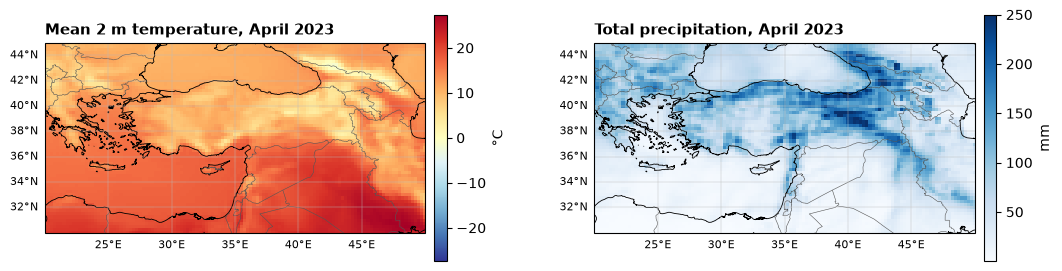

In [4]:
fig, axes = map_axes(1, 2, figsize=(13, 4))
plot_field(ds.t2m_c.mean("time"), axes[0], cmap="RdYlBu_r", label="°C")
axes[0].set_title("Mean 2 m temperature, April 2023")
plot_field(ds.tp_mm.sum("time"), axes[1], cmap="Blues", label="mm", vmax=250)
axes[1].set_title("Total precipitation, April 2023")
save(fig, "01_t2m_precip_maps.png")

The temperature map mostly shows the **topography**: the Anatolian plateau and
the eastern highlands are much colder than the coasts at the same latitude.
Precipitation was highest over the mountains of eastern and south-eastern
Anatolia, the Zagros and the Caucasus, and along the eastern Black Sea coast.
In these places moist air is forced to rise over the mountains (orographic
lifting). The Syrian and North African deserts and the Aegean received very
little rain this month.

## 4. Selecting a single time: the wettest day

First we find the day with the most precipitation over the region, then we draw
the mean sea-level pressure (isobars) and 10 m wind for that day.

wettest day: 2023-04-12 (7.5 mm region mean)


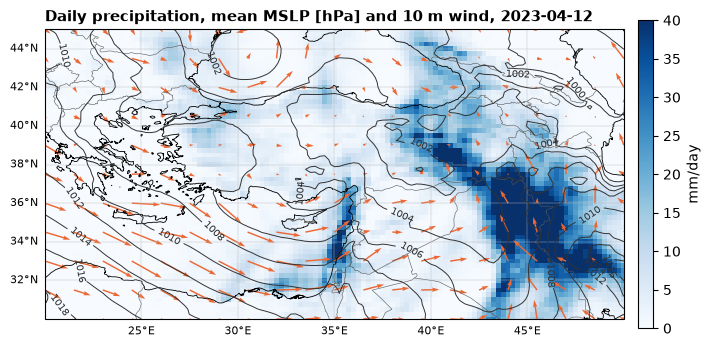

In [5]:
daily_tp = ds.tp_mm.resample(time="1D").sum()
region_tp = daily_tp.mean(["latitude", "longitude"])
wettest = region_tp.idxmax("time").dt.strftime("%Y-%m-%d").item()
print("wettest day:", wettest, f"({float(region_tp.max()):.1f} mm region mean)")

day = ds.sel(time=wettest).mean("time")
fig, ax = map_axes(figsize=(9, 5))
plot_field(daily_tp.sel(time=wettest), ax, cmap="Blues", label="mm/day", vmax=40)
cs = ax.contour(day.longitude, day.latitude, day.msl_hpa, levels=range(990, 1030, 2),
                colors="#333333", linewidths=0.7, transform=PLATE)
ax.clabel(cs, fontsize=7, fmt="%d")
s = 6
ax.quiver(day.longitude[::s], day.latitude[::s], day.u10[::s, ::s], day.v10[::s, ::s],
          transform=PLATE, scale=200, width=0.0025, color=COLORS[1])
ax.set_title(f"Daily precipitation, mean MSLP [hPa] and 10 m wind, {wettest}")
save(fig, "01_wettest_day.png")

## 5. Time series at cities

`.sel(latitude=..., longitude=..., method="nearest")` picks the nearest grid
point. Remember: this is the value of a ~28 km grid box, not of a station.

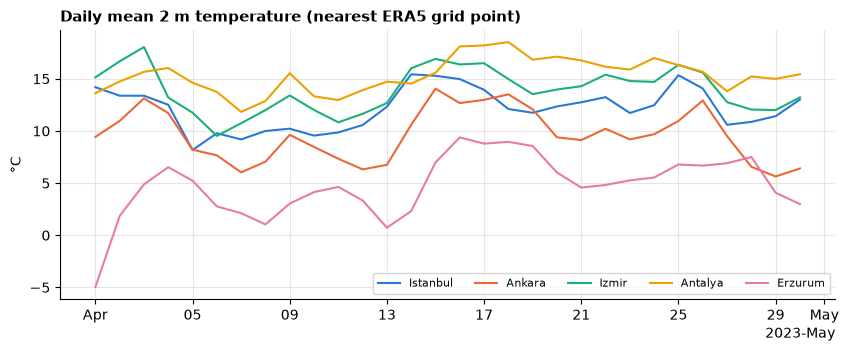

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for i, (city, (lat, lon)) in enumerate(cfg.CITIES.items()):
    ds.t2m_c.sel(latitude=lat, longitude=lon, method="nearest") \
        .resample(time="1D").mean().plot(ax=ax, color=COLORS[i], label=city)
ax.set_ylabel("°C")
ax.set_xlabel("")
ax.set_title("Daily mean 2 m temperature (nearest ERA5 grid point)")
ax.legend(ncol=5, fontsize=8)
save(fig, "01_city_timeseries.png")

## 6. Diurnal cycle with `groupby`

`groupby("time.hour")` collects all values at 00 UTC, all at 01 UTC, and so on.
Turkey is UTC+3, so 12 UTC is 15:00 local time.

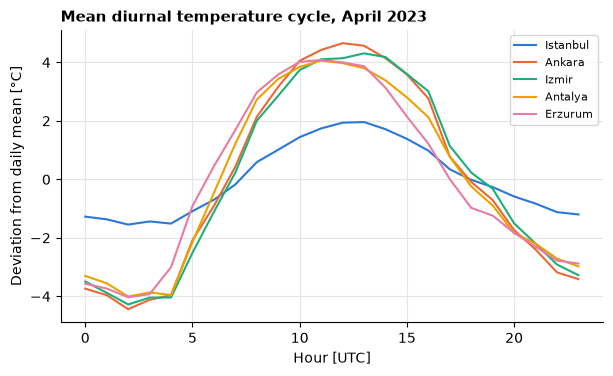

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, (city, (lat, lon)) in enumerate(cfg.CITIES.items()):
    cycle = ds.t2m_c.sel(latitude=lat, longitude=lon, method="nearest").groupby("time.hour").mean()
    ax.plot(cycle.hour, cycle - cycle.mean(), color=COLORS[i], label=city)
ax.set_xlabel("Hour [UTC]")
ax.set_ylabel("Deviation from daily mean [°C]")
ax.set_title("Mean diurnal temperature cycle, April 2023")
ax.legend(fontsize=8)
save(fig, "01_diurnal_cycle.png")

In [8]:
for city, (lat, lon) in cfg.CITIES.items():
    c = ds.t2m_c.sel(latitude=lat, longitude=lon, method="nearest").groupby("time.hour").mean()
    print(f"{city:9s} diurnal range {float(c.max() - c.min()):4.1f} °C")

Istanbul  diurnal range  3.5 °C
Ankara    diurnal range  9.1 °C
Izmir     diurnal range  8.6 °C
Antalya   diurnal range  8.1 °C
Erzurum   diurnal range  8.1 °C


Istanbul has the smallest daily temperature range: its grid box is strongly
influenced by the sea, which heats and cools slowly because of its large heat
capacity. Inland Ankara has a range almost three times larger, a classic example
of **continentality**.

**References:** Hersbach et al. (2020), *Q. J. R. Meteorol. Soc.*, 146, 1999–2049;
Hoyer & Hamman (2017), *J. Open Res. Softw.*, 5(1), 10;
Alduchov & Eskridge (1996), *J. Appl. Meteor.*, 35, 601–609. Full list in the README.